In [1]:
# Block 1
%load_ext autoreload
%autoreload 1

# Watch the modules these cells call into
%aimport utility
%aimport config
%aimport Detector
%aimport stacker
%aimport stacker_set

import os

# Keras reads the backend before it is imported
os.environ["KERAS_BACKEND"] = "torch"

import json
import time

import numpy as np
import pandas as pd

import keras

# torch backend runtime, imported only to report the device Keras will use
import torch

import config
import utility

import Detector
import stacker
import stacker_set
from stacker import (
    BASE_LABELS,
    BASE_MODELS,
    INPUT_CHANNELS,
    Stacker,
    architecture_defaults,
    base_raw,
    base_records,
    build_stacker,
    features_for,
    oracle_recall,
    run_variant,
)

In [2]:
# Block 2
LESION_TYPE = "mass"

# Both stackers run the full out-of-fold split
STACKER_FOLDS = config.OOF_FOLDS

# Two stackers over one out-of-fold split: the grid rasterises, the set stacker reads tokens
GRID_TAG = "prior"
GRID_ARCHITECTURE = architecture_defaults() | {"objectness_prior": True}
GRID_NAME = f"{stacker.MODEL_NAME}_{GRID_TAG}"
GRID_LABEL = "Stacker (grid)"

SET_TAG = "w128"
SET_ARCHITECTURE = stacker_set.architecture_defaults() | {"width": 128}
SET_NAME = f"{stacker_set.MODEL_NAME}_{SET_TAG}"
SET_LABEL = "Stacker (set, 128)"

STACKERS = {GRID_NAME: GRID_LABEL, SET_NAME: SET_LABEL}
RETAINED_NAME = SET_NAME
EPOCHS = config.SET_NUM_EPOCHS

# Display only: the Block 13 union panel ranks each detector's top boxes instead of cutting
PANEL_TOP_K = 2

for name in STACKERS:
    config.FOLD_LAYOUT.setdefault(name, (config.STACKER_WORKSPACE, ".keras"))

# Seeds python, numpy and torch, and pins the cuDNN algorithm choice, so two runs agree
utility.set_deterministic()

config.STACKER_WORKSPACE.mkdir(parents=True, exist_ok=True)
config.MODELS_ROOT.mkdir(parents=True, exist_ok=True)

device = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu"

print(f"Backend    : {keras.backend.backend()}")
print(f"Device     : {device}")
print(f"Base models: {', '.join(BASE_LABELS[model] for model in BASE_MODELS)}")
print(
    f"Grid input : {stacker.GRID_SIZE} x {stacker.GRID_SIZE} x {stacker.ANCHOR_COUNT} "
    f"x {INPUT_CHANNELS} per mammogram"
)
print(f"Grid arch  : {GRID_ARCHITECTURE}")
print(f"Set arch   : {SET_ARCHITECTURE}")
print(f"Retained   : {RETAINED_NAME}")
print(
    f"Schedule   : {EPOCHS} epochs, batch {config.SET_BATCH_SIZE}, lr {config.SET_LR}, "
    f"{config.SET_K} candidates per model"
)
print(f"Export     : stacker floor {config.STACKER_SCORE_THRESHOLD}, operating threshold unset")
print(f"Folds      : {STACKER_FOLDS} of {config.OOF_FOLDS}")
print(f"Workspace  : {config.STACKER_WORKSPACE}")


class NullProgress:
    # Stand-in for a progress bar, so a block that is not streaming stays quiet
    def reset(self, total=None, **kwargs):
        pass

    def set_description(self, *args, **kwargs):
        pass

    def set_postfix_str(self, *args, **kwargs):
        pass

    def update(self, count=1):
        pass

    def close(self):
        pass


QUIET = NullProgress()

Backend    : torch
Device     : NVIDIA GeForce RTX 3060 Laptop GPU
Base models: CNN, Faster R-CNN, YOLO
Grid input : 96 x 96 x 4 x 21 per mammogram
Grid arch  : {'filters': 64, 'stages': 2, 'head_filters': 32, 'kernel': 3, 'double': False, 'projection': True, 'anchor_width': True, 'class_stop_gradient': False, 'norm': 'layer', 'objectness_prior': True, 'candidate_supervision': False}
Set arch   : {'k': 10, 'width': 128, 'heads': 4, 'blocks': 2, 'box_head': 'none', 'norm': 'layer', 'agreement': False, 'prior_scale': True, 'dropout': 0.0}
Retained   : stacker_set_w128
Schedule   : 20 epochs, batch 16, lr 0.001, 10 candidates per model
Export     : stacker floor 0.05, operating threshold unset
Folds      : (0, 1, 2, 3, 4) of (0, 1, 2, 3, 4)
Workspace  : C:\Users\User\Desktop\sch work\fyp\04_stacker_workspace


In [3]:
# Block 3
# Load metadata and build the per-mammogram split
metadata = pd.read_csv(config.PROJECT_ROOT / f"{LESION_TYPE}_metadata.csv")

display(metadata.head())

print(f"Rows: {len(metadata):,}")
print(f"Unique mammograms: {metadata['full_image'].nunique():,}")
print(f"Unique lesions: {metadata['mask_image'].nunique():,}")

groups = utility.group_mammograms(metadata)

# The stacker consumes the detectors' out-of-fold predictions, so it lives on trainval too
trainval_df = groups[groups["split"] == "trainval"].reset_index(drop=True)
test_df = groups[groups["split"] == "test"].reset_index(drop=True)

print(f"Trainval: {len(trainval_df):,} mammograms, folds {trainval_df['fold'].value_counts().sort_index().to_dict()}")
print(f"Test    : {len(test_df):,} mammograms, held out")

,patient_id,breast density,left or right breast,image view,abnormality id,abnormality type,mass shape,mass margins,assessment,pathology,...,split,fold,full_image,crop_image,mask_image,breast_mask,breast_xmin,breast_ymin,breast_xmax,breast_ymax
0,P_00016,4,LEFT,CC,1,mass,IRREGULAR,SPICULATED,5,MALIGNANT,...,test,-1,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,198,0,471,1023
1,P_00016,4,LEFT,MLO,1,mass,IRREGULAR,SPICULATED,5,MALIGNANT,...,test,-1,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,0,0,374,1023
2,P_00017,2,LEFT,CC,1,mass,ROUND,CIRCUMSCRIBED,4,MALIGNANT,...,trainval,0,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,0,0,554,1023
3,P_00017,2,LEFT,MLO,1,mass,ROUND,ILL_DEFINED,4,MALIGNANT,...,trainval,0,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,0,0,576,1023
4,P_00032,3,RIGHT,CC,1,mass,ROUND,OBSCURED,0,BENIGN,...,trainval,2,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,153,0,528,1023


Rows: 1,696
Unique mammograms: 1,592
Unique lesions: 1,696
Trainval: 1,272 mammograms, folds {0: 264, 1: 248, 2: 248, 3: 253, 4: 259}
Test    : 320 mammograms, held out


In [4]:
# Block 4
# The grid holds, per mammogram, the three detectors' rasterised candidates and the ground truth
grid_stacker = Stacker(lesion_type=LESION_TYPE)
grid_stacker.prepare_fold_data(trainval_df, config.VAL_FOLD, LESION_TYPE)

grid = grid_stacker.grid

image_id = utility.mammogram_id(trainval_df.iloc[0]["full_image"])
entry = grid[image_id]
features = features_for(entry["raster"])

print(f"Mammograms in the grid : {len(grid):,}")
print(f"Input tensor           : {features.shape}")
print(f"Non-zero input values  : {int((features != 0).sum()):,} of {features.size:,}")
print(f"Ground-truth boxes     : {len(entry['gt_boxes'])}")

counts = pd.DataFrame(
    {
        BASE_LABELS[model]: [
            sum(len(grid[key]["raster"][model][0]) for key in grid) / len(grid),
            max(len(grid[key]["raster"][model][0]) for key in grid),
        ]
        for model in BASE_MODELS
    },
    index=["candidates per mammogram", "most in one mammogram"],
)

display(counts.round(2))

Mammograms in the grid : 1,272
Input tensor           : (96, 96, 4, 21)
Non-zero input values  : 114 of 774,144
Ground-truth boxes     : 1


,CNN,Faster R-CNN,YOLO
candidates per mammogram,13.69,3.2,3.04
most in one mammogram,34.00,14.0,13.00


In [5]:
# Block 5
# Build the grid stacker and inspect one training batch
grid_stacker.build()

train_df, val_df = utility.oof_split(trainval_df, config.VAL_FOLD)
train_loader = grid_stacker.dataset(train_df)
inputs, targets = train_loader[0]

print(f"Batch input      : {inputs.shape}")
print(f"Objectness shape : {targets['objectness'].shape}")
print(f"Box shape        : {targets['box'].shape}")
print(f"Class shape      : {targets['classes'].shape}")
print(f"Positives        : {int((targets['objectness'] == 1).sum()):,}")
print(f"Negatives        : {int((targets['objectness'] == 0).sum()):,}")
print(f"Ignored          : {int((targets['objectness'] == -1).sum()):,}")
print(f"Train batches    : {len(train_loader):,}")

Batch input      : (8, 96, 96, 4, 21)
Objectness shape : (8, 96, 96, 4)
Box shape        : (8, 96, 96, 4, 5)
Class shape      : (8, 96, 96, 4, 2)
Positives        : 170
Negatives        : 3,400
Ignored          : 291,342
Train batches    : 126


In [6]:
# Block 6
# The grid stacker, one fold at a time. A completed fold is skipped, so a re-run resumes
print(
    f"Loss  : objectness BCE, box weight {config.STACKER_BOX_LOSS_WEIGHT}, class weight {config.STACKER_CLASS_LOSS_WEIGHT}"
)
print(
    f"Class : weight {config.STACKER_CLASS_LOSS_WEIGHT_START} -> {config.STACKER_CLASS_LOSS_WEIGHT} "
    f"over {config.STACKER_CLASS_LOSS_RAMP_EPOCHS} epochs"
)
print(
    f"Export: candidates at floor {config.STACKER_SCORE_THRESHOLD}, "
    f"predictions at {config.STACKER_INFERENCE_SCORE_THRESHOLD}"
)

grid_summary = {}

for fold in STACKER_FOLDS:
    grid_summary[fold] = run_variant(
        trainval_df, LESION_TYPE, GRID_ARCHITECTURE, tag=GRID_TAG, fold=fold, epochs=EPOCHS
    )

Loss  : objectness BCE, box weight 1.0, class weight 21.0
Class : weight 1.0 -> 21.0 over 5 epochs
Export: candidates at floor 0.05, predictions at 0.5
Fold 0: complete (val AP50 0.6161, 3660 records), skipping
Epoch | Loss   | obj    | box    | cls    | AP50   | mAP50  | P      | R      | F1     | Det
1     | 0.3594 | 0.1498 | 0.0603 | 0.0365 | 0.3444 | 0.1076 | 0.0515 | 0.6121 | 0.0950 | 12.7
2     | 0.3523 | 0.0629 | 0.0154 | 0.0329 | 0.5392 | 0.2913 | 0.0939 | 0.7367 | 0.1666 | 8.3
3     | 0.4309 | 0.0557 | 0.0133 | 0.0286 | 0.6161 | 0.4598 | 0.1181 | 0.7829 | 0.2052 | 7.1 | Saved best model
4     | 0.5079 | 0.0534 | 0.0128 | 0.0261 | 0.5493 | 0.3972 | 0.1659 | 0.7367 | 0.2708 | 4.7
5     | 0.6101 | 0.0537 | 0.0128 | 0.0259 | 0.4886 | 0.3657 | 0.0892 | 0.6940 | 0.1580 | 8.3
6     | 0.6548 | 0.0518 | 0.0123 | 0.0244 | 0.5614 | 0.3694 | 0.0903 | 0.7509 | 0.1612 | 8.9
7     | 0.6151 | 0.0514 | 0.0113 | 0.0227 | 0.5712 | 0.3873 | 0.1589 | 0.7509 | 0.2623 | 5.0
8     | 0.5921 | 0.0481 |

In [7]:
# Block 7
# Each fold's saved checkpoint predicts the fold it never saw
for fold in STACKER_FOLDS:
    paths = config.fold_paths(GRID_NAME, LESION_TYPE, fold)
    fold_df = trainval_df[trainval_df["fold"] == fold].reset_index(drop=True)

    predictor = Stacker(GRID_ARCHITECTURE, LESION_TYPE, tag=GRID_TAG)
    predictor.grid = grid
    predictor.load(paths["model"])

    records = predictor.detections(fold_df, desc=f"Fold {fold} export", progress=QUIET)
    utility.write_atomically(lambda path: records.to_csv(path, index=False), paths["records"])

    print(f"Fold {fold}: {len(records):,} records over {len(fold_df):,} mammograms")

Fold 0: 3,660 records over 264 mammograms
Fold 1: 2,764 records over 248 mammograms
Fold 2: 3,288 records over 248 mammograms
Fold 3: 3,478 records over 253 mammograms
Fold 4: 4,586 records over 259 mammograms


In [8]:
# Block 8
# The set stacker reads the same candidates as tokens and reuses the boxes it is handed
set_tokens = stacker_set.build_tokens(trainval_df, LESION_TYPE, STACKER_FOLDS, top_k=SET_ARCHITECTURE["k"])

set_detector = stacker_set.StackerSet(SET_ARCHITECTURE, LESION_TYPE, tag=SET_TAG)
set_detector.tokens = set_tokens
set_detector.prepare_model()

sample = set_tokens[utility.mammogram_id(trainval_df.iloc[0]["full_image"])]

print(f"Mammograms  : {len(set_tokens):,}")
print(
    f"Tokens each : {len(sample['tokens'])} = {len(stacker_set.BASE_MODELS)} models x {SET_ARCHITECTURE['k']} candidates"
)
print(
    f"Parameters  : {set_detector.model.count_params():,} against "
    f"{grid_stacker.model.count_params():,} for the grid stacker"
)
print(
    f"First image : {int((sample['objectness'] == 1).sum())} positive, "
    f"{int((sample['objectness'] == 0).sum())} negative, {int((sample['objectness'] == -1).sum())} ignored"
)

Mammograms  : 1,272
Tokens each : 30 = 3 models x 10 candidates
Parameters  : 267,528 against 2,091,804 for the grid stacker
First image : 4 positive, 23 negative, 3 ignored


In [9]:
# Block 9
# Retained stacker over every fold, each predicting the mammograms it never saw
set_started = time.time()

for fold in STACKER_FOLDS:
    set_detector.fit_fold(trainval_df, fold, LESION_TYPE, epochs=EPOCHS)

set_detector.export_folds(trainval_df, LESION_TYPE, folds=STACKER_FOLDS)

print(f"{RETAINED_NAME}: {time.time() - set_started:.0f} s, {set_detector.model.count_params():,} parameters")

set_manifest = utility.read_oof_manifest(config.oof_manifest_path(RETAINED_NAME, LESION_TYPE))
set_folds = []

for fold in STACKER_FOLDS:
    entry = set_manifest["folds"][str(fold)]
    history = pd.read_csv(config.fold_paths(RETAINED_NAME, LESION_TYPE, fold)["history"])

    set_folds.append(
        {
            "fold": fold,
            "params": set_detector.model.count_params(),
            "best epoch": entry["best_epoch"],
            "AP50 best": entry["best_val_ap50"],
            "AP50 last5": history["ap50"].tail(5).mean(),
            "mAP50 last5": history["ap50_macro"].tail(5).mean(),
            "candidates/img": entry["record_count"] / entry["image_count"],
        }
    )

# The saved checkpoint is the per-fold best epoch, so the last-5 mean is the selection-free read
display(pd.DataFrame(set_folds).set_index("fold").round(4))

Fold 0: complete (val AP50 0.6444 at epoch 18), skipping
Epoch | Loss   | obj    | box    | cls    | AP50   | mAP50  | P      | R      | F1     | Det
1     | 0.5455 | 0.4743 | 0.8568 | 0.1424 | 0.6070 | 0.2288 | 0.6680 | 0.5943 | 0.6290 | 0.9
2     | 0.4771 | 0.3599 | 0.3728 | 0.1143 | 0.6068 | 0.2545 | 0.7083 | 0.6050 | 0.6526 | 0.9
3     | 0.5168 | 0.3438 | 0.3488 | 0.1115 | 0.6332 | 0.3971 | 0.6772 | 0.6868 | 0.6820 | 1.1
4     | 0.5467 | 0.3424 | 0.3429 | 0.1021 | 0.6277 | 0.3618 | 0.4919 | 0.7544 | 0.5955 | 1.6
5     | 0.5357 | 0.3333 | 0.4016 | 0.1012 | 0.6262 | 0.4354 | 0.5812 | 0.7260 | 0.6456 | 1.3
6     | 0.5302 | 0.3334 | 0.4231 | 0.0984 | 0.6233 | 0.3701 | 0.5735 | 0.7082 | 0.6338 | 1.3
7     | 0.5237 | 0.3275 | 0.3949 | 0.0981 | 0.6304 | 0.3667 | 0.6495 | 0.6726 | 0.6608 | 1.1
8     | 0.5409 | 0.3264 | 0.4293 | 0.1073 | 0.6231 | 0.3763 | 0.5413 | 0.7224 | 0.6189 | 1.4
9     | 0.5187 | 0.3215 | 0.4628 | 0.0986 | 0.6209 | 0.4000 | 0.5274 | 0.7189 | 0.6084 | 1.5
10    | 0.511

,params,best epoch,AP50 best,AP50 last5,mAP50 last5,candidates/img
fold,,,,,,
0,267528,18,0.6444,0.6344,0.4500,5.1288
1,267528,1,0.5636,0.5450,0.3700,5.2137
2,267528,6,0.5666,0.5596,0.3521,4.5968
3,267528,8,0.6301,0.5881,0.3672,4.6640
4,267528,17,0.6176,0.6124,0.3986,4.9344


In [10]:
# Block 10
# Coverage check: every record comes from its own held-out fold and no test mammogram appears
records_by_fold = utility.oof_records(
    {fold: config.fold_paths(RETAINED_NAME, LESION_TYPE, fold)["records"] for fold in STACKER_FOLDS}
)
manifest = utility.read_oof_manifest(config.oof_manifest_path(RETAINED_NAME, LESION_TYPE))

print(f"Folds complete: {sorted(manifest['folds'])}")

trainval_ids = pd.Series([utility.mammogram_id(path) for path in trainval_df["full_image"]], index=trainval_df.index)
test_ids = {utility.mammogram_id(path) for path in test_df["full_image"]}

covered = []

for fold, frame in records_by_fold.items():
    fold_ids = set(frame["image_id"])
    expected_ids = set(trainval_ids[trainval_df["fold"] == fold])

    covered.extend(sorted(fold_ids))

    print(
        f"Fold {fold}: {frame['image_id'].nunique():,} mammograms, {len(frame):,} records, "
        f"outside its own fold: {len(fold_ids - expected_ids)}"
    )

print(f"OOF mammograms: {len(covered):,} rows, {len(set(covered)):,} unique of {len(trainval_df):,} trainval")
print(f"Test mammograms inside the OOF records: {len(set(covered) & test_ids)}")

manifest_df = pd.DataFrame.from_dict(manifest["folds"], orient="index").sort_index()
manifest_df.index.name = "fold"

display(manifest_df)

Folds complete: ['0', '1', '2', '3', '4']
Fold 0: 264 mammograms, 1,354 records, outside its own fold: 0
Fold 1: 248 mammograms, 1,293 records, outside its own fold: 0
Fold 2: 248 mammograms, 1,140 records, outside its own fold: 0
Fold 3: 253 mammograms, 1,180 records, outside its own fold: 0
Fold 4: 259 mammograms, 1,278 records, outside its own fold: 0
OOF mammograms: 1,272 rows, 1,272 unique of 1,272 trainval
Test mammograms inside the OOF records: 0


,fold,seed,epochs,best_epoch,best_val_ap50,record_count,image_count,exported,fingerprint,candidate_count
fold,,,,,,,,,,
0,0,42,20,18,0.644372,1354,264,True,950cd77a54ba,1354
1,1,42,20,1,0.563598,1293,248,True,950cd77a54ba,1293
2,2,42,20,6,0.566591,1140,248,True,950cd77a54ba,1140
3,3,42,20,8,0.630108,1180,253,True,950cd77a54ba,1180
4,4,42,20,17,0.617573,1278,259,True,950cd77a54ba,1278


In [11]:
# Block 11
# Both stackers scored on the pooled out-of-fold records; P/R/F1 are at an evaluation cut
stacker_records = {name: base_records(LESION_TYPE, name, STACKER_FOLDS) for name in STACKERS}
all_ids = [utility.mammogram_id(path) for path in trainval_df["full_image"]]
fold_of = dict(zip(all_ids, trainval_df["fold"]))

rows = []

for name, label in STACKERS.items():
    frame = stacker_records[name]
    metrics = Detector.detection_metrics(
        base_raw(frame, grid, all_ids), config.CNN_IOU_THRESHOLD, config.STACKER_SCORE_THRESHOLD
    )

    per_fold = [
        Detector.detection_metrics(
            base_raw(frame, grid, [image_id for image_id in all_ids if fold_of[image_id] == fold]),
            config.CNN_IOU_THRESHOLD,
            config.STACKER_SCORE_THRESHOLD,
        )["ap50"]
        for fold in STACKER_FOLDS
    ]

    rows.append(
        {
            "model": label,
            "AP50": metrics["ap50"],
            "mAP50": metrics["ap50_macro"],
            **dict(zip(config.CLASS_NAMES, metrics["ap50_per_class"])),
            "P": metrics["precision"],
            "R": metrics["recall"],
            "F1": metrics["f1"],
            "Det": metrics["det_per_image"],
            "candidates/img": len(frame) / len(all_ids),
            "oracle": oracle_recall(frame, grid, all_ids),
            "fold AP50 mean": float(np.mean(per_fold)),
            "fold AP50 std": float(np.std(per_fold)),
        }
    )

display(pd.DataFrame(rows).set_index("model").round(4))

,AP50,mAP50,benign,malignant,P,R,F1,Det,candidates/img,oracle,fold AP50 mean,fold AP50 std
model,,,,,,,,,,,,
Stacker (grid),0.5799,0.3792,0.3375,0.4210,0.0597,0.7838,0.111,13.9748,13.9748,0.7838,0.5826,0.0221
"Stacker (set, 128)",0.5999,0.3605,0.2801,0.4408,0.1734,0.7993,0.285,4.9096,4.9096,0.7993,0.6044,0.0332


In [12]:
# Block 12
# Full-trainval stackers for the held-out comparison; an existing checkpoint is reused
import final_retrain

FULL_STACKERS = {name: final_retrain.load_or_train(name) for name in ("stacker_grid", "stacker_set")}

display(
    pd.DataFrame(
        [
            {"model": name, "checkpoint": path.name, "MB": round(path.stat().st_size / 1e6, 1)}
            for name, path in FULL_STACKERS.items()
        ]
    ).set_index("model")
)

stacker_grid: mass_stacker_grid_full.keras is already on disk, not retraining
stacker_set: mass_stacker_set_full.keras is already on disk, not retraining


,checkpoint,MB
model,,
stacker_grid,mass_stacker_grid_full.keras,25.2
stacker_set,mass_stacker_set_full.keras,3.4


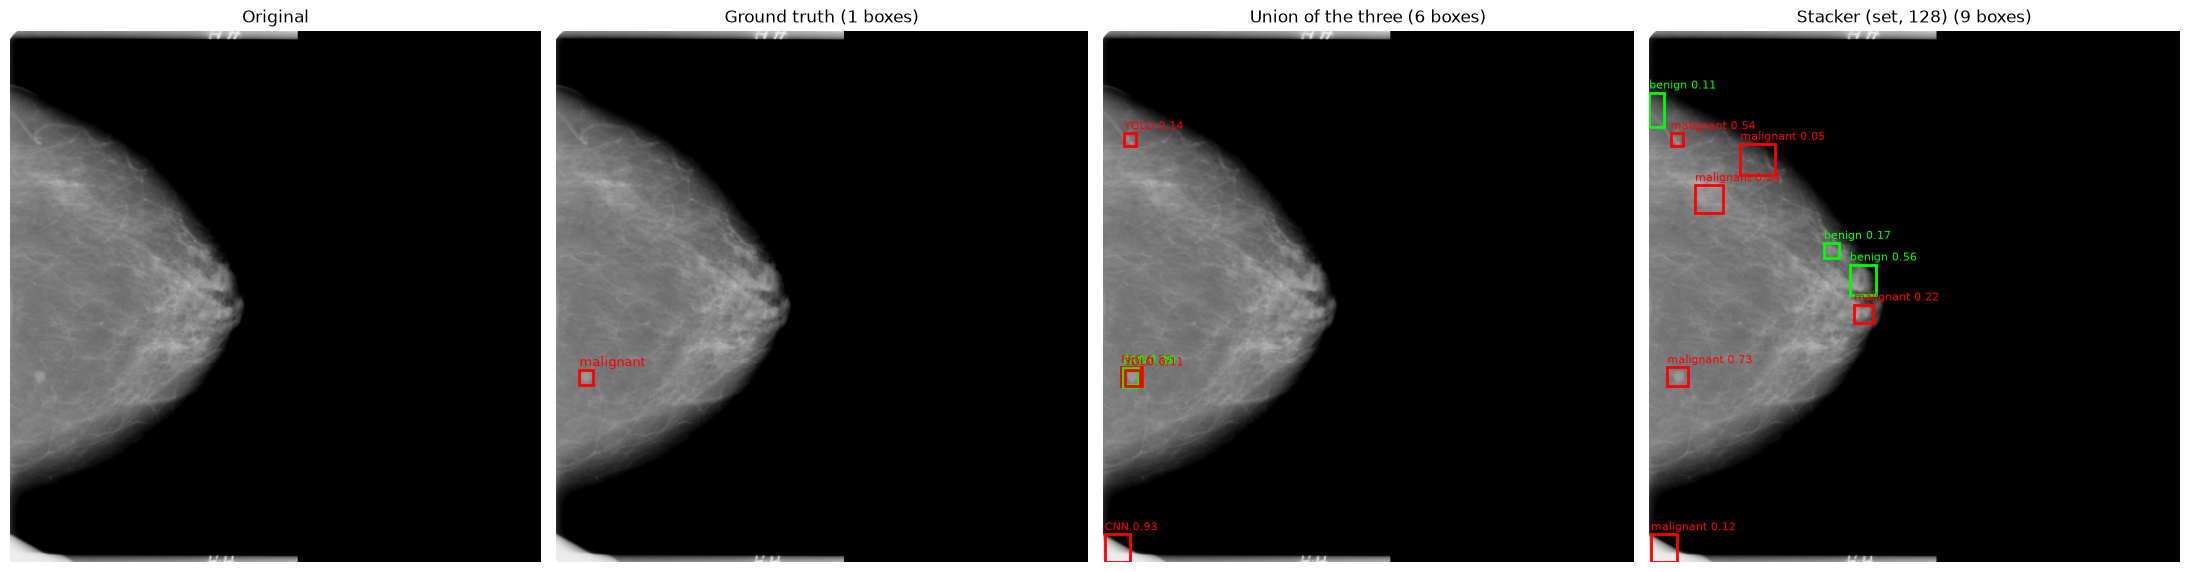

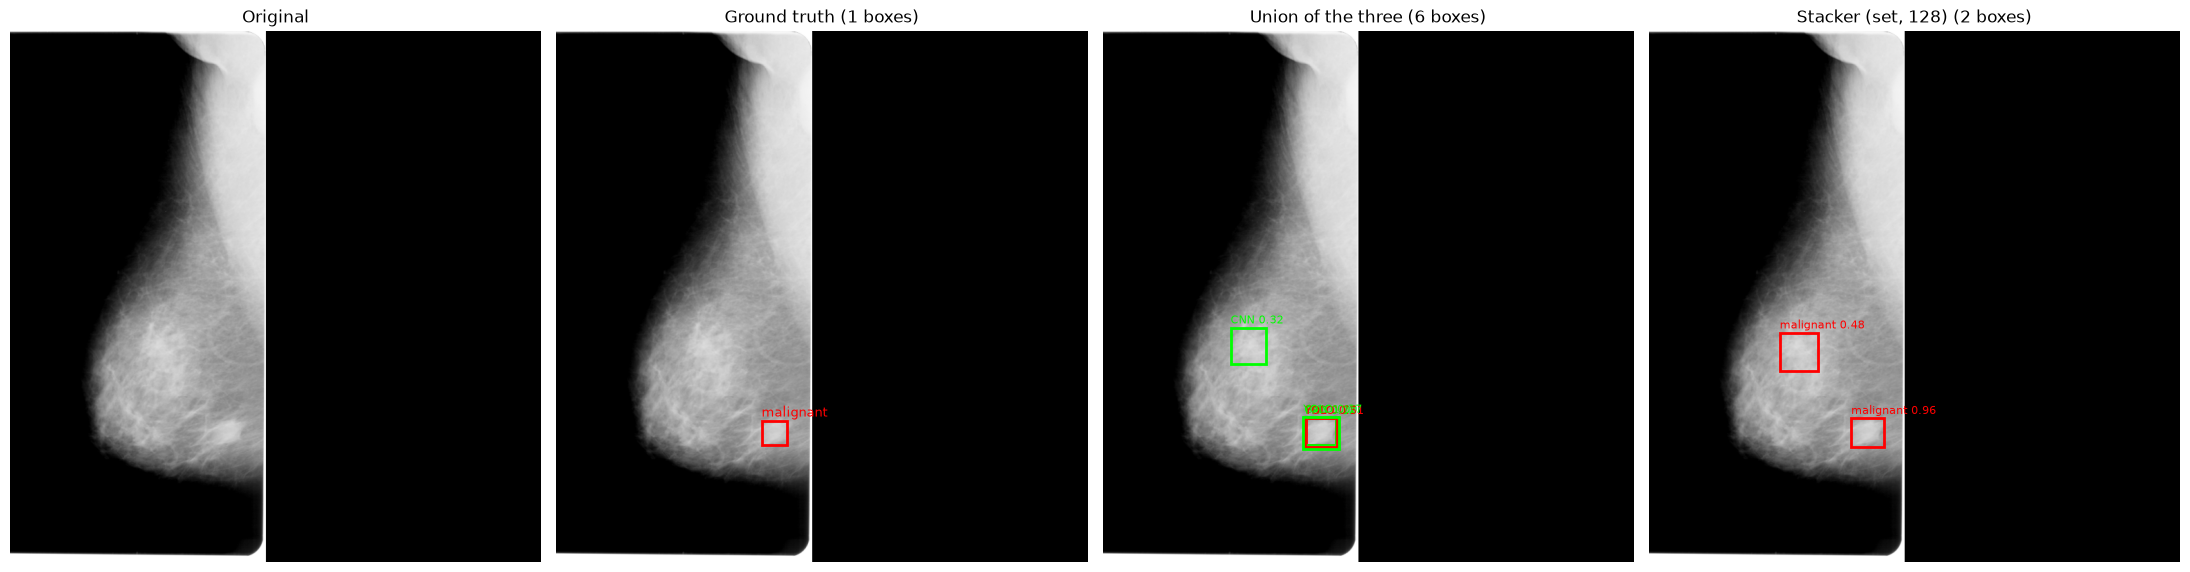

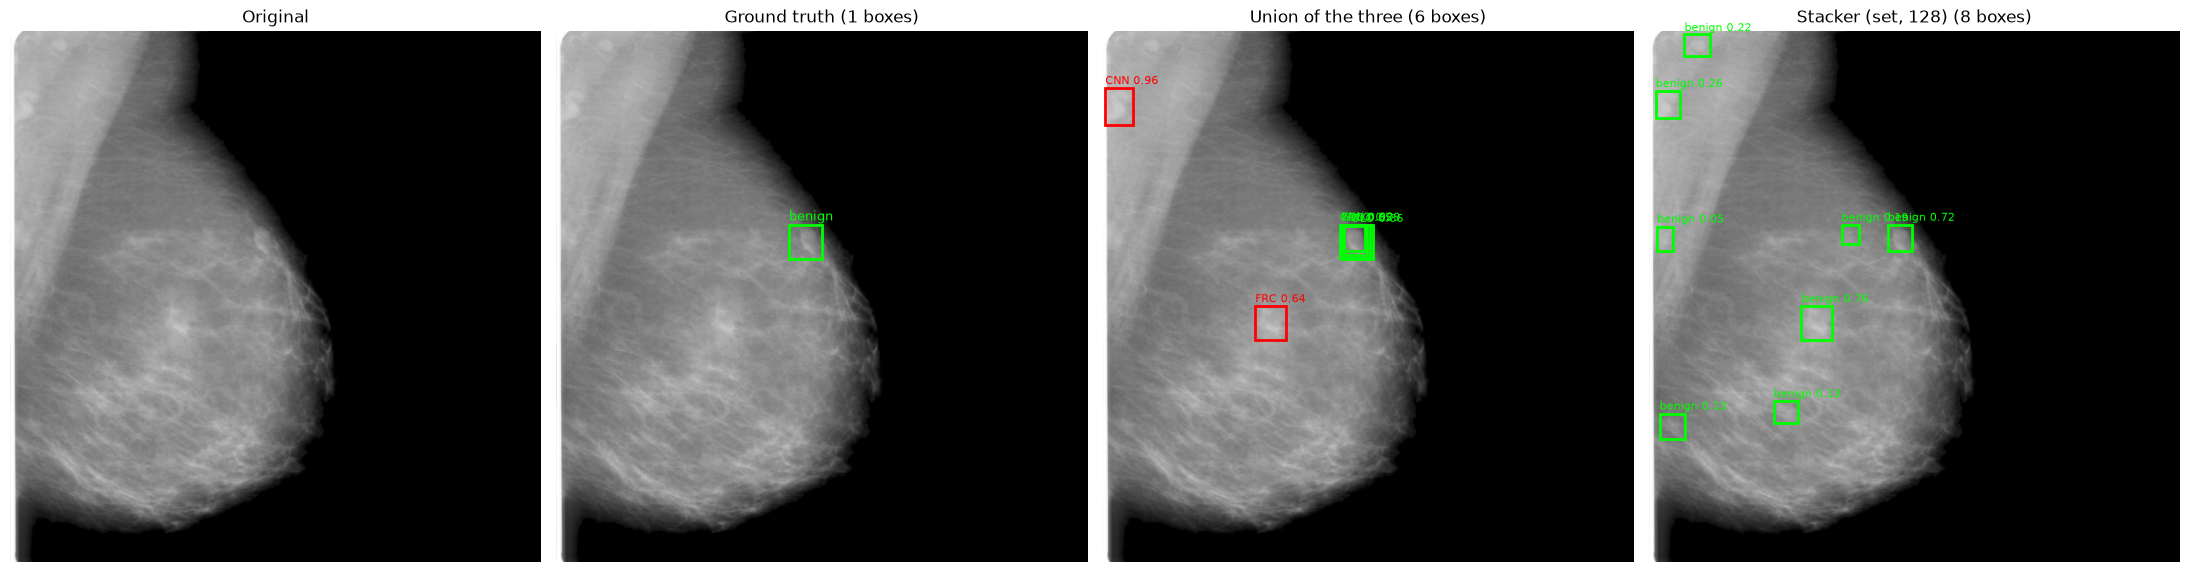

In [13]:
# Block 13
# One mammogram per figure: the ground truth, the three detectors ranked, and the retained stacker
val_fold_df = trainval_df[trainval_df["fold"] == config.VAL_FOLD].reset_index(drop=True)

scorer = stacker_set.StackerSet(SET_ARCHITECTURE, LESION_TYPE, tag=SET_TAG)
scorer.tokens = set_tokens
scorer.load(config.fold_model_path(RETAINED_NAME, LESION_TYPE, config.VAL_FOLD))

detector_records = {model: base_records(LESION_TYPE, model, STACKER_FOLDS) for model in BASE_MODELS}
short_names = {"cnn": "CNN", "faster_rcnn": "FRC", "yolo": "YOLO"}
columns = ["x1", "y1", "x2", "y2"]

for index in np.linspace(0, len(val_fold_df) - 1, 3, dtype=int):
    row = val_fold_df.iloc[index]
    image_id = utility.mammogram_id(row["full_image"])

    image, gt_boxes, gt_labels, boxes, scores, labels = scorer.predict_image(row)

    union_boxes, union_scores, union_labels, union_captions = [], [], [], []

    for model in BASE_MODELS:
        frame = detector_records[model]
        frame = frame[frame["image_id"] == image_id].nlargest(PANEL_TOP_K, "score")

        union_boxes.append(frame[columns].to_numpy(np.float32))
        union_scores.append(frame["score"].to_numpy(np.float32))
        union_labels.append(frame["class_label"].to_numpy(np.int64))
        union_captions.extend(f"{short_names[model]} {value:.2f}" for value in frame["score"])

    panels = [
        (
            "Union of the three",
            np.concatenate(union_boxes),
            np.concatenate(union_scores),
            np.concatenate(union_labels),
            union_captions,
        ),
        (SET_LABEL, boxes, scores, labels),
    ]

    utility.visualize_comparison(image, gt_boxes, gt_labels, panels, config.CLASS_NAMES)

In [14]:
# Block 14
# Operating surface: a score threshold and a per-image cap swept together over the capped pool
thresholds = (0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 0.9)
caps = (1, 2, 3, 5, 8, 0)

retained_records = base_records(LESION_TYPE, RETAINED_NAME, STACKER_FOLDS)
retained_ids = [utility.mammogram_id(path) for path in trainval_df["full_image"]]
retained_raw = base_raw(retained_records, grid, retained_ids)

surface = []

for cap in caps:
    capped = utility.cap_detections(retained_raw, cap)

    for threshold in thresholds:
        metrics = Detector.detection_metrics(capped, config.CNN_IOU_THRESHOLD, threshold)

        surface.append(
            {
                "cap": "none" if not cap else cap,
                "threshold": threshold,
                "AP50": metrics["ap50"],
                "mAP50": metrics["ap50_macro"],
                "P": metrics["precision"],
                "R": metrics["recall"],
                "F1": metrics["f1"],
                "Det": metrics["det_per_image"],
            }
        )

display(pd.DataFrame(surface).set_index(["cap", "threshold"]).round(4))

AP50   mAP50       P       R      F1     Det
cap  threshold                                                
1    0.05       0.5354  0.3335  0.6612  0.6207  0.6403  1.0000
     0.10       0.5354  0.3335  0.6612  0.6207  0.6403  1.0000
     0.20       0.5354  0.3335  0.6648  0.6207  0.6420  0.9945
     0.30       0.5354  0.3335  0.6723  0.6207  0.6454  0.9835
     0.50       0.5354  0.3335  0.6993  0.5956  0.6433  0.9072
     0.70       0.5354  0.3335  0.7845  0.4945  0.6066  0.6714
     0.90       0.5354  0.3335  0.9032  0.2480  0.3891  0.2925
2    0.05       0.5769  0.3492  0.3906  0.7247  0.5076  1.9764
     0.10       0.5769  0.3492  0.3966  0.7232  0.5123  1.9426
     0.20       0.5769  0.3492  0.4192  0.7196  0.5297  1.8286
     0.30       0.5769  0.3492  0.4495  0.7129  0.5514  1.6895
     0.50       0.5769  0.3492  0.5509  0.6635  0.6019  1.2830
     0.70       0.5769  0.3492  0.7156  0.5144  0.5985  0.7657
     0.90       0.5769  0.3492  0.8880  0.2517  0.3922  0.3019
3    0.05       0.5920  0.3563  0.2820  0.7661  0.4122  2.8939
     0.10       0.5920  0.3563  0.2978  0.7638  0.4286  2.7319
     0.20       0.5920  0.3563  0.3388  0.7520  0.4671  2.3648
     0.30       0.5920  0.3563  0.3916  0.7387  0.5119  2.0094
     0.50       0.5920  0.3563  0.5299  0.6745  0.5935  1.3561
     0.70       0.5920  0.3563  0.7141  0.5144  0.5980  0.7673
     0.90       0.5920  0.3563  0.8880  0.2517  0.3922  0.3019
5    0.05       0.5978  0.3593  0.1984  0.7889  0.3171  4.2351
     0.10       0.5978  0.3593  0.2334  0.7845  0.3597  3.5810
     0.20       0.5978  0.3593  0.3033  0.7638  0.4342  2.6824
     0.30       0.5978  0.3593  0.3736  0.7439  0.4974  2.1211
     0.50       0.5978  0.3593  0.5277  0.6745  0.5922  1.3616
     0.70       0.5978  0.3593  0.7134  0.5144  0.5978  0.7681
     0.90       0.5978  0.3593  0.8880  0.2517  0.3922  0.3019
8    0.05       0.5999  0.3605  0.1752  0.7993  0.2873  4.8608
     0.10       0.5999  0.3605  0.2226  0.7882  0.3471  3.7720
     0.20       0.5999  0.3605  0.3004  0.7646  0.4313  2.7115
     0.30       0.5999  0.3605  0.3731  0.7439  0.4969  2.1242
     0.50       0.5999  0.3605  0.5277  0.6745  0.5922  1.3616
     0.70       0.5999  0.3605  0.7134  0.5144  0.5978  0.7681
     0.90       0.5999  0.3605  0.8880  0.2517  0.3922  0.3019
none 0.05       0.5999  0.3605  0.1734  0.7993  0.2850  4.9096
     0.10       0.5999  0.3605  0.2224  0.7882  0.3469  3.7752
     0.20       0.5999  0.3605  0.3004  0.7646  0.4313  2.7115
     0.30       0.5999  0.3605  0.3731  0.7439  0.4969  2.1242
     0.50       0.5999  0.3605  0.5277  0.6745  0.5922  1.3616
     0.70       0.5999  0.3605  0.7134  0.5144  0.5978  0.7681
     0.90       0.5999  0.3605  0.8880  0.2517  0.3922  0.3019

# Findings

Numbers are the pooled out-of-fold result over the 1,272 held-out mammograms of the five folds,
both stackers scored the same way: AP50 over candidates at the 0.05 floor, then precision, recall
and F1 at that stacker's own operating threshold. One seed each, so a gap under about 0.03 is
inside the noise. Tables are Block 11 (scorecard), Block 12 (full-trainval checkpoints) and
Block 14 (threshold and cap surface).

| Stacker | AP50 | mAP50 | P | R | F1 | Det/img | candidates/img |
| ------- | ---: | ----: | -: | -: | -: | ------: | -------------: |
| set, 128 | **0.5999** | 0.3605 | 0.5277 | 0.6745 | 0.5922 | 1.36 | 4.89 |
| grid | 0.5799 | **0.3792** | 0.1581 | 0.7572 | 0.2616 | 5.10 | 13.97 |

- The two disagree about which is better, and the disagreement is wider than the gap between
  them. Each wins one of the two headline metrics by about 0.02, against a fold-to-fold spread of
  0.022 on the grid and 0.033 on the set stacker, and their detections per image at the operating
  threshold differ by 3.7x. The pooled numbers do not separate them, so the final model is picked
  in `05_comparison.ipynb`, where both are scored against the three detectors on the held-out
  test set.
- Both are re-rankers, not detectors, so the candidate set they are handed is their ceiling. The
  set stacker's own oracle recall is 0.7993, essentially the 0.7860 a plain NMS over the union of
  the three reaches: it reorders the union well and cannot recover a lesion that none of the
  three proposed.
- They sit on opposite sides of the detections per image the task wants. The grid stacker is
  already inside the 3 to 5 band at 5.10 boxes with precision 0.16, while the set stacker sits at
  1.36 with precision 0.53. Bringing the set stacker into the band means dropping its threshold
  to 0.1, which halves its precision, 0.53 to 0.22, at the same AP50. Block 14 maps that surface:
  AP50 is set by the cap rather than the threshold, and the cap is nearly free down to the
  dataset's lesion ceiling, 0.5978 at 5 and 0.5920 at 3, while a cap of 2 costs 0.023 and a cap
  of 1 costs 0.065.

## Full-trainval retrain

- Each stacker exists in two forms: the five fold checkpoints scored above, and one checkpoint
  retrained on all 1,272 trainval mammograms. Block 12 loads the second form and trains it only
  if it is missing.
- The two forms are not interchangeable. Retraining on all of trainval trades the fold ensemble
  for about 255 more mammograms of training data, which is a real question rather than a free
  upgrade, so both are kept and `05_comparison.ipynb` scores them on the held-out test set.

## Two choices the drawing leaves open

Neither is forced by the architecture diagram. Every detector contributes rasterised candidates
rather than its own dense output, because only the CNN has a dense output to give; and the grid
stacker's `ConvBlock` is one convolution plus normalisation and ReLU rather than the detector
trunk's double convolution.
